# Homework 1
## Finding Similar Items: Textually Similar Documents

本 Notebook 用 Twenty Newsgroups 数据集完成作业要求的文本相似度实验。

实现的阶段包括：

1. Shingling
2. 直接计算 Jaccard similarity
3. MinHashing
4. 比较 MinHash signatures
5. 可选的 LSH：banding 找候选对，再按相似度阈值筛选
6. 不同文档规模下的运行时间实验

核心算法都在 `similarity.py` 中。Notebook 只负责调用算法、展示中间结果和绘图，这样代码和报告使用的是同一套实现。

## 报告信息

### 数据集

使用 UCI Machine Learning Repository 的 Twenty Newsgroups 数据集中的 mini 版本，共 20 个新闻组、2,000 篇文档。

- 数据集页面：<https://archive.ics.uci.edu/dataset/113/twenty+newsgroups>
- 直接下载：<https://archive.ics.uci.edu/static/public/113/twenty+newsgroups.zip>

下载的 ZIP 中有 `mini_newsgroups.tar.gz`。把它解压到 `TW1` 的上一级目录下的 `twenty_newsgroups/mini/`，得到 `twenty_newsgroups/mini/mini_newsgroups/<新闻组>/<文档>`。数据集不包含在提交的 ZIP 中。

### 构建和运行

程序只使用 Python 标准库，需要 Python 3.10 或更高版本，没有构建步骤。Notebook 另外需要 `notebook` 和 `matplotlib`。在 `TW1` 目录中：

```text
python main.py --sizes 10 100 1000 --lsh     完整实验，也可以用 run.sh、run.ps1 或 run.bat
python -m unittest -v                        单元测试，不需要数据集
```

### 命令行参数

| 参数 | 默认值 | 含义 |
|---|---|---|
| `--data-dir` | `../twenty_newsgroups/mini/mini_newsgroups` | 数据集目录 |
| `--categories` | 全部新闻组 | 只读取指定的新闻组 |
| `--sizes` | `10 100 1000` | 要测试的文档数量 |
| `--k` | `5` | 字符 shingle 的长度 |
| `--num-hashes` | `100` | MinHash signature 的长度 |
| `--threshold` | `0.3` | Jaccard 相似度阈值 s |
| `--body-only` | 关闭 | 只使用正文，不使用 Subject |
| `--lsh` | 关闭 | 运行可选的 LSH 阶段 |
| `--lsh-bands`、`--lsh-rows` | 根据阈值自动选择 | LSH 的 band 数量和每个 band 的行数 |
| `--output-dir` | `results` | 保存 CSV 结果的目录 |

### 实现概览

| 作业中的类 | 实现 | 说明 |
|---|---|---|
| Shingling | `similarity.Shingling` | 字符 k-shingle，用 SHA-1 的前 8 个字节作为哈希值，返回去重并排序的列表 |
| CompareSets | `similarity.CompareSets` | 两个哈希值集合的 Jaccard similarity |
| MinHashing | `similarity.MinHashing` | n 个线性哈希函数 $(ax+b) \bmod p$，每个函数取最小值 |
| CompareSignatures | `similarity.CompareSignatures` | 两个 signature 相同分量的比例 |
| LSH | `similarity.LSH` | banding 加哈希桶得到候选对，再按 signature 相似度阈值筛选 |

相似度阈值使用 $s = 0.3$。作业页面中的 0.8 是示例值。这个数据集里的文档是不同作者写的新闻组消息，相似的文档主要来自引用回复和交叉发布，在 1,000 篇的样本中，Jaccard 达到 0.8 的只有 4 对内容完全相同的交叉发布消息，所以选择 0.3 才能观察到有意义的相似对。

## 1. 环境和数据路径

请从 `TW1` 文件夹启动 Jupyter。下面的代码会从当前工作目录向上查找 `similarity.py`，所以从 `TW1` 的子目录启动也能找到项目文件。数据集默认位于 `TW1` 的上一级目录。

In [1]:
# 标准库用于路径、组合和表格数据
from pathlib import Path
from itertools import combinations
from collections import Counter
import sys
import time

# matplotlib 只用于绘图，不参与核心算法
import matplotlib.pyplot as plt

# 从当前目录向上查找 similarity.py，避免依赖某一台电脑的绝对路径。
PROJECT_DIR = Path.cwd()
for candidate in [PROJECT_DIR, *PROJECT_DIR.parents]:
    if (candidate / "similarity.py").exists():
        PROJECT_DIR = candidate
        break
else:
    raise FileNotFoundError("请从 TW1 目录或它的子目录启动 Notebook")

DATA_DIR = PROJECT_DIR.parent / "twenty_newsgroups" / "mini" / "mini_newsgroups"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# 将项目目录加入模块搜索路径，这样 Notebook 可以导入 similarity.py 和 main.py
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from similarity import (
    CompareSets,
    CompareSignatures,
    LSH,
    MinHashing,
    Shingling,
    balanced_sample,
    load_documents,
)
from main import format_ratio, run_experiment

# 只打印相对路径，输出不依赖某一台电脑的目录结构。
print("Project directory:", PROJECT_DIR.name)
print("Dataset directory:", DATA_DIR.relative_to(PROJECT_DIR.parent).as_posix())
print("Dataset exists:", DATA_DIR.is_dir())
assert DATA_DIR.is_dir(), "找不到数据集，请按上面“数据集”一节的说明下载并解压"

Project directory: TW1
Dataset directory: twenty_newsgroups/mini/mini_newsgroups
Dataset exists: True


## 2. 查看数据集

数据集的目录名就是新闻组类别。每个文件是一篇 Usenet 文档。读取时使用 Latin-1，默认保留 Subject 和正文，并去掉容易造成噪声的其他邮件头。

In [2]:
# 读取全部 2,000 篇 mini 文档。
# 这一步只读取文本，不会复制或修改数据集文件。
documents = load_documents(DATA_DIR, include_subject=True)

category_counts = Counter(document.category for document in documents)
print("Number of documents:", len(documents))
print("Number of categories:", len(category_counts))
print("First five categories:")
for category, count in sorted(category_counts.items())[:5]:
    print(f"  {category}: {count}")

sample_document = documents[0]
print("\nExample document:", sample_document.name)
print(sample_document.text[:800])

Number of documents: 2000
Number of categories: 20
First five categories:
  alt.atheism: 100
  comp.graphics: 100
  comp.os.ms-windows.misc: 100
  comp.sys.ibm.pc.hardware: 100
  comp.sys.mac.hardware: 100

Example document: alt.atheism/51121
re: [soc.motss, et al.] "princeton axes matching funds for boy scouts" in article <n4hy.93apr5120934@harder.ccr-p.ida.org>, n4hy@harder.ccr-p.ida.org (bob mcgwier) writes: |> [1] however, i hate economic terrorism and political correctness |> worse than i hate this policy. |> [2] a more effective approach is to stop donating |> to any organizating that directly or indirectly supports gay rights issues |> until they end the boycott on funding of scouts. can somebody reconcile the apparent contradiction between [1] and [2]? -- rob strom, strom@watson.ibm.com, (914) 784-7641 ibm research, 30 saw mill river road, p.o. box 704, yorktown heights, ny 10598


## 3. Shingling

这里使用长度为 `k=5` 的字符 shingles。每个 shingle 会被转换为稳定的整数哈希值，并且同一个 shingle 只保留一次。

In [3]:
# 对一篇文档演示 Shingling
shingling = Shingling(k=5)
example_shingles = shingling.shingles(sample_document.text)

print("Document:", sample_document.name)
print("Cleaned text length:", len(sample_document.text))
print("Number of unique shingles:", len(example_shingles))
print("First 20 hashed shingles:")
print(example_shingles[:20])

Document: alt.atheism/51121
Cleaned text length: 657
Number of unique shingles: 611
First 20 hashed shingles:
[25975315044961623, 28680041385666441, 33875345137779096, 34476731288997712, 36481857364804862, 58217864160553433, 71030997760095672, 86509723561404521, 92696785002546017, 98761666537063181, 107103088783510940, 142447511903182440, 194589318020048164, 233255180438685453, 251421048860496727, 339886150591155758, 342118637570375898, 389499983851320204, 459163699780191312, 477604132689130643]


## 4. 直接计算 Jaccard similarity

Jaccard similarity 是准确基准：

\[
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
\]

Notebook 中的 exact Jaccard 结果会作为 MinHash 和 LSH 的比较基准。

In [4]:
# 选择同一新闻组中的两篇文档，方便观察主题相近的文本
same_category = [
    document for document in documents if document.category == "comp.graphics"
][:2]

if len(same_category) < 2:
    same_category = documents[:2]

first_set = set(shingling.shingles(same_category[0].text))
second_set = set(shingling.shingles(same_category[1].text))
intersection_size = len(first_set & second_set)
union_size = len(first_set | second_set)
exact_jaccard = CompareSets.jaccard(first_set, second_set)

print("First document:", same_category[0].name)
print("Second document:", same_category[1].name)
print("Intersection size:", intersection_size)
print("Union size:", union_size)
print("Exact Jaccard:", round(exact_jaccard, 4))

First document: comp.graphics/37916
Second document: comp.graphics/37921
Intersection size: 48
Union size: 1001
Exact Jaccard: 0.048


## 5. MinHashing

MinHash 将一个可能很大的 shingle 集合压缩成固定长度的 signature。

signature 中每一个位置对应一个确定性的哈希函数。两个文档的 signature 在相同位置相等的比例，就是 Jaccard similarity 的估计值。

In [5]:
# 使用 100 个哈希函数生成两个 MinHash signatures
minhashing = MinHashing(signature_length=100, seed=42)
first_signature = minhashing.signature(first_set)
second_signature = minhashing.signature(second_set)
minhash_estimate = CompareSignatures.similarity(first_signature, second_signature)

print("Signature length:", len(first_signature))
print("Exact Jaccard:", round(exact_jaccard, 4))
print("MinHash estimate:", round(minhash_estimate, 4))
print("Absolute error:", round(abs(exact_jaccard - minhash_estimate), 4))

Signature length: 100
Exact Jaccard: 0.048
MinHash estimate: 0.05
Absolute error: 0.002


## 6. 在多篇文档上比较 exact Jaccard 和 MinHash

单独比较一对文档不够。下面使用 10 篇平衡抽样的文档，计算所有文档对，并观察平均误差。

In [6]:
# balanced_sample 会从不同新闻组轮流选择文档，保证小样本不只来自一个主题
small_documents = balanced_sample(documents, 10)
small_shingles = {
    document.name: shingling.shingles(document.text)
    for document in small_documents
}
small_signatures = {
    name: minhashing.signature(values)
    for name, values in small_shingles.items()
}

comparison_rows = []
for first_name, second_name in combinations(sorted(small_shingles), 2):
    exact = CompareSets.jaccard(small_shingles[first_name], small_shingles[second_name])
    estimate = CompareSignatures.similarity(
        small_signatures[first_name], small_signatures[second_name]
    )
    comparison_rows.append({
        "first": first_name,
        "second": second_name,
        "exact_jaccard": exact,
        "minhash_estimate": estimate,
        "absolute_error": abs(exact - estimate),
    })

comparison_rows.sort(key=lambda row: row["exact_jaccard"], reverse=True)
print("Number of document pairs:", len(comparison_rows))
for row in comparison_rows[:10]:
    print(
        row["first"], "<->", row["second"],
        "exact=", round(row["exact_jaccard"], 4),
        "minhash=", round(row["minhash_estimate"], 4),
        "error=", round(row["absolute_error"], 4),
    )

small_mean_error = sum(row["absolute_error"] for row in comparison_rows) / len(comparison_rows)
print("\nMean absolute error:", round(small_mean_error, 4))

Number of document pairs: 45
comp.os.ms-windows.misc/10003 <-> rec.autos/101564 exact= 0.0434 minhash= 0.03 error= 0.0134
comp.os.ms-windows.misc/10003 <-> rec.motorcycles/103129 exact= 0.0392 minhash= 0.03 error= 0.0092
comp.sys.mac.hardware/50419 <-> rec.autos/101564 exact= 0.0382 minhash= 0.04 error= 0.0018
comp.os.ms-windows.misc/10003 <-> rec.sport.baseball/102590 exact= 0.0378 minhash= 0.05 error= 0.0122
comp.os.ms-windows.misc/10003 <-> comp.sys.mac.hardware/50419 exact= 0.035 minhash= 0.05 error= 0.015
alt.atheism/51121 <-> comp.os.ms-windows.misc/10003 exact= 0.0322 minhash= 0.06 error= 0.0278
rec.motorcycles/103129 <-> rec.sport.baseball/102590 exact= 0.0318 minhash= 0.03 error= 0.0018
alt.atheism/51121 <-> rec.sport.baseball/102590 exact= 0.0309 minhash= 0.02 error= 0.0109
comp.sys.mac.hardware/50419 <-> rec.motorcycles/103129 exact= 0.0307 minhash= 0.01 error= 0.0207
rec.autos/101564 <-> rec.motorcycles/103129 exact= 0.0306 minhash= 0.02 error= 0.0106

Mean absolute error: 

## 7. LSH

LSH 把每个 signature 切成 `bands` 个 band，每个 band 有 `rows` 个分量。两个 signature 只要在任意一个 band 上完全相同，就落入同一个哈希桶，成为候选对。Jaccard similarity 为 $s$ 的一对文档成为候选对的概率是

$$
P(s) = 1 - (1 - s^{rows})^{bands}
$$

这条 S 形曲线的陡升位置大约在 $(1/bands)^{1/rows}$，所以 `bands` 和 `rows` 必须配合阈值来选。`LSH.choose_bands` 在 `bands * rows = 100` 的组合里，选 `rows` 最大、同时让相似度恰好等于阈值的文档对仍有至少 95% 的概率成为候选对的那一组。

得到候选对之后，`LSH.similar_pairs` 只对候选对比较 signature，保留相同分量比例不低于阈值的对。这就是作业描述的完整 LSH 步骤。

下面先看不同参数组合在阈值 0.3 处的检出概率，再在 100 篇同主题文档上运行 LSH。

In [7]:
threshold = 0.3

# signature 长度为 100 时可用的 (bands, rows) 组合，以及它们在阈值处的检出概率
print("bands rows  approx. threshold  P(candidate | s=0.3)")
for rows in [1, 2, 4, 5, 10]:
    bands = 100 // rows
    print(
        f"{bands:5d} {rows:4d}  {(1 / bands) ** (1 / rows):17.3f}  "
        f"{LSH.detection_probability(threshold, bands, rows):20.3f}"
    )

lsh_bands, lsh_rows = LSH.choose_bands(signature_length=100, threshold=threshold)
print(f"\nChosen for threshold {threshold}: bands={lsh_bands}, rows={lsh_rows}")
print("Chosen for threshold 0.8:", LSH.choose_bands(signature_length=100, threshold=0.8))

# 为了让 LSH 演示包含同主题文档，选择 comp.graphics 的 100 篇文档。
# 规模实验仍然使用全部新闻组，二者用途不同。
lsh_documents = [
    document for document in documents if document.category == "comp.graphics"
][:100]
if len(lsh_documents) < 2:
    lsh_documents = documents[:100]

lsh_shingling = Shingling(k=5)
lsh_minhashing = MinHashing(signature_length=100, seed=42)
lsh_shingles = {
    document.name: frozenset(lsh_shingling.shingles(document.text))
    for document in lsh_documents
}
lsh_signatures = {
    name: lsh_minhashing.signature(values)
    for name, values in lsh_shingles.items()
}

# 准确基准：比较全部文档对的 exact Jaccard
true_similar = {
    (first_name, second_name)
    for first_name, second_name in combinations(sorted(lsh_shingles), 2)
    if CompareSets.jaccard(lsh_shingles[first_name], lsh_shingles[second_name]) >= threshold
}

# LSH：banding 得到候选对，再按 signature 相似度筛选
lsh_candidates = LSH.candidates(lsh_signatures, bands=lsh_bands, rows=lsh_rows)
lsh_pairs = LSH.similar_pairs(lsh_signatures, threshold=threshold)
true_positives = len(set(lsh_pairs) & true_similar)

all_pairs = len(lsh_documents) * (len(lsh_documents) - 1) // 2
print("\nLSH demonstration documents:", len(lsh_documents))
print("All document pairs:", all_pairs)
print("Exact similar pairs (Jaccard >= threshold):", len(true_similar))
print("LSH candidate pairs:", len(lsh_candidates))
print("LSH pairs with signature similarity >= threshold:", len(lsh_pairs))
print("LSH true positives:", true_positives)
if true_similar:
    print("LSH recall:", round(true_positives / len(true_similar), 4))
for (first_name, second_name), estimate in sorted(lsh_pairs.items()):
    exact = CompareSets.jaccard(lsh_shingles[first_name], lsh_shingles[second_name])
    print(f"  {first_name} <-> {second_name}: signature={estimate:.2f}, exact={exact:.4f}")

bands rows  approx. threshold  P(candidate | s=0.3)
  100    1              0.010                 1.000
   50    2              0.141                 0.991
   25    4              0.447                 0.184
   20    5              0.549                 0.047
   10   10              0.794                 0.000

Chosen for threshold 0.3: bands=50, rows=2
Chosen for threshold 0.8: (20, 5)



LSH demonstration documents: 100
All document pairs: 4950
Exact similar pairs (Jaccard >= threshold): 1
LSH candidate pairs: 236
LSH pairs with signature similarity >= threshold: 1
LSH true positives: 1
LSH recall: 1.0
  comp.graphics/38856 <-> comp.graphics/38921: signature=0.57, exact=0.5631


## 8. 规模实验

规模实验使用全部新闻组的平衡样本，测试 10、100 和 1,000 篇文档。

运行时间分别记录：

- Shingling
- MinHash
- 文档对比较
- LSH，包括 banding 和对候选对的 signature 比较
- 总时间

直接比较的文档对数量是 \(n(n-1)/2\)，所以它会随着文档数量近似平方增长。全部文档对的比较只是为了得到准确基准和评估 LSH，LSH 本身不需要它。

In [8]:
# 使用 10、100、1,000 篇文档进行可扩展性测试。
# 不指定 bands 和 rows，run_experiment 会根据阈值自动选择。
scalability_rows = []
for size in [10, 100, 1000]:
    selected = balanced_sample(documents, size)
    summary, _ = run_experiment(
        selected,
        Shingling(k=5),
        MinHashing(signature_length=100, seed=42),
        threshold=0.3,
        run_lsh=True,
    )
    scalability_rows.append(summary)

print("docs     pairs  similar  LSH cand.  LSH pairs  precision  recall")
for row in scalability_rows:
    print(
        f"{row['documents']:4d} {row['pairs']:9d} {row['similar_pairs']:8d} "
        f"{row['lsh_candidates']:10d} {row['lsh_similar_pairs']:10d} "
        f"{format_ratio(row['lsh_precision']):>10} {format_ratio(row['lsh_recall']):>7}"
    )

print("\nRunning time in seconds")
print("docs  shingling   minhash  all pairs       LSH     total")
for row in scalability_rows:
    print(
        f"{row['documents']:4d} {row['shingling_seconds']:10.4f} {row['minhash_seconds']:9.4f} "
        f"{row['pair_comparison_seconds']:10.4f} {row['lsh_seconds']:9.4f} {row['total_seconds']:9.4f}"
    )

# 保存一份和 Notebook 内容一致的汇总结果，方便复核
import csv
summary_path = RESULTS_DIR / "notebook_scalability.csv"
with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=scalability_rows[0].keys(), lineterminator="\n")
    writer.writeheader()
    writer.writerows(scalability_rows)
print("\nSaved:", summary_path.relative_to(PROJECT_DIR).as_posix())

docs     pairs  similar  LSH cand.  LSH pairs  precision  recall
  10        45        0          3          0        n/a     n/a
 100      4950        1        544          1     1.0000  1.0000
1000    499500       39      53906         42     0.8810  0.9487

Running time in seconds
docs  shingling   minhash  all pairs       LSH     total
  10     0.0290    0.2599     0.0008    0.0001    0.2899
 100     0.1333    1.8071     0.1071    0.0032    2.0508
1000     1.1535   16.1875    11.0397    0.2303   28.6356

Saved: results/notebook_scalability.csv


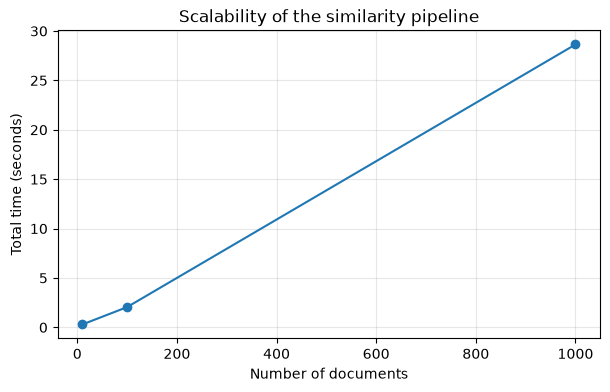

In [9]:
# 绘制规模和总运行时间
sizes = [row["documents"] for row in scalability_rows]
total_times = [row["total_seconds"] for row in scalability_rows]

plt.figure(figsize=(7, 4))
plt.plot(sizes, total_times, marker="o")
plt.xlabel("Number of documents")
plt.ylabel("Total time (seconds)")
plt.title("Scalability of the similarity pipeline")
plt.grid(True, alpha=0.3)
plt.show()

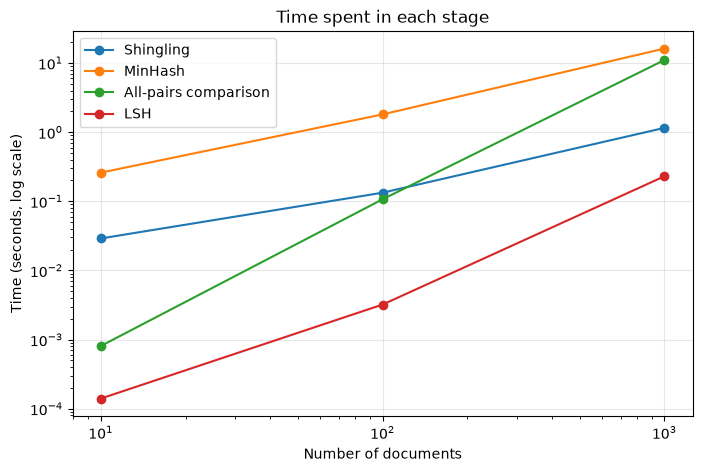

In [10]:
# 绘制各个阶段的时间，帮助判断主要开销来自哪里
stage_names = [
    ("shingling_seconds", "Shingling"),
    ("minhash_seconds", "MinHash"),
    ("pair_comparison_seconds", "All-pairs comparison"),
    ("lsh_seconds", "LSH"),
]

plt.figure(figsize=(8, 5))
for field, label in stage_names:
    plt.plot(sizes, [row[field] for row in scalability_rows], marker="o", label=label)
# 各阶段相差几个数量级，使用对数坐标才能同时看清
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of documents")
plt.ylabel("Time (seconds, log scale)")
plt.title("Time spent in each stage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 9. 参数对比

下面比较 `k=5` 和 `k=10`，以及不同 signature 长度对 MinHash 误差的影响。为了让实验时间适中，参数对比使用 100 篇文档。

In [11]:
# 比较 shingle 长度和 signature 长度
parameter_rows = []
parameter_documents = balanced_sample(documents, 100)

for k in [5, 10]:
    for signature_length in [100, 200]:
        summary, pair_rows = run_experiment(
            parameter_documents,
            Shingling(k=k),
            MinHashing(signature_length=signature_length, seed=42),
            threshold=0.3,
            run_lsh=False,
        )
        mean_error = sum(row["absolute_error"] for row in pair_rows) / len(pair_rows)
        parameter_rows.append({
            "k": k,
            "signature_length": signature_length,
            "mean_absolute_error": mean_error,
            "total_seconds": summary["total_seconds"],
        })

for row in parameter_rows:
    print(row)

{'k': 5, 'signature_length': 100, 'mean_absolute_error': 0.012349002474904445, 'total_seconds': 2.0839343331754208}
{'k': 5, 'signature_length': 200, 'mean_absolute_error': 0.00855175590170593, 'total_seconds': 3.916754915844649}
{'k': 10, 'signature_length': 100, 'mean_absolute_error': 0.002093973322471959, 'total_seconds': 2.6142225000075996}
{'k': 10, 'signature_length': 200, 'mean_absolute_error': 0.0014600761294513173, 'total_seconds': 5.070968915708363}


In [12]:
# 根据前面的实验生成结论中引用的数字
largest = scalability_rows[-1]
smallest = scalability_rows[0]
print(f"规模从 {smallest['documents']} 增加到 {largest['documents']} 篇时，总时间从 {smallest['total_seconds']:.2f}s 变为 {largest['total_seconds']:.2f}s。")
print(f"在 {largest['documents']} 篇文档上，MinHash 用时 {largest['minhash_seconds']:.2f}s，全部文档对比较用时 {largest['pair_comparison_seconds']:.2f}s，LSH 用时 {largest['lsh_seconds']:.2f}s。")
print(f"在 {largest['documents']} 篇文档上，exact Jaccard 不低于 0.3 的文档对有 {largest['similar_pairs']} 个。")
print(f"LSH 使用 {largest['lsh_bands']} bands x {largest['lsh_rows']} rows，生成 {largest['lsh_candidates']} 个候选对，占全部 {largest['pairs']} 对的 {largest['lsh_candidates'] / largest['pairs']:.1%}，候选对召回率为 {format_ratio(largest['lsh_candidate_recall'])}。")
print(f"按 signature 相似度筛选后得到 {largest['lsh_similar_pairs']} 对，precision 为 {format_ratio(largest['lsh_precision'])}，recall 为 {format_ratio(largest['lsh_recall'])}。")
print(f"10 篇文档上的平均 MinHash absolute error 为 {small_mean_error:.4f}。")

规模从 10 增加到 1000 篇时，总时间从 0.29s 变为 28.64s。
在 1000 篇文档上，MinHash 用时 16.19s，全部文档对比较用时 11.04s，LSH 用时 0.23s。
在 1000 篇文档上，exact Jaccard 不低于 0.3 的文档对有 39 个。
LSH 使用 50 bands x 2 rows，生成 53906 个候选对，占全部 499500 对的 10.8%，候选对召回率为 1.0000。
按 signature 相似度筛选后得到 42 对，precision 为 0.8810，recall 为 0.9487。
10 篇文档上的平均 MinHash absolute error 为 0.0115。


## 10. 结论

下面的数字来自本 Notebook 的这一次运行，参数为 `k=5`、signature length=100、threshold=0.3。运行环境是一台 macOS 笔记本电脑，Python 3.13，单进程，只使用标准库。运行时间会随电脑性能变化。

**运行时间**

| 文档数 | 文档对 | Shingling | MinHash | 全部文档对比较 | LSH | 总时间 |
|---:|---:|---:|---:|---:|---:|---:|
| 10 | 45 | 0.03 s | 0.26 s | 0.001 s | 0.0001 s | 0.29 s |
| 100 | 4,950 | 0.13 s | 1.81 s | 0.11 s | 0.003 s | 2.05 s |
| 1,000 | 499,500 | 1.15 s | 16.19 s | 11.04 s | 0.23 s | 28.64 s |

- Shingling 和 MinHash 的时间随文档数量线性增长。MinHash 需要对每个 shingle 计算 100 个哈希值，在纯 Python 中是单篇文档上最贵的一步。
- 全部文档对比较的时间随文档数量平方增长。文档数量增加 10 倍，这一阶段的时间增加约 100 倍，在更大的语料上它会成为主要开销。
- LSH 在 1,000 篇文档上只用 0.23 秒。它只比较 53,906 个候选对的 signature，占全部 499,500 对的 10.8%，不需要计算任何一对的 exact Jaccard。

**相似文档**

- 1,000 篇文档中有 39 对的 exact Jaccard 不低于 0.3，其中 4 对的内容完全相同，是交叉发布到多个新闻组的同一条消息。
- 10 篇的样本来自 10 个不同的新闻组，没有达到阈值的文档对。100 篇的样本中有 1 对。

**MinHash 的准确度**

- 10 篇文档的 45 个文档对上，MinHash 估计值的平均绝对误差为 0.0115。
- 在 100 篇文档上，signature 长度从 100 增加到 200，平均绝对误差从 0.0123 降到 0.0086，运行时间约增加一倍。
- `k=10` 时不相关文档之间共享的 shingle 更少，exact Jaccard 更接近 0，所以绝对误差也更小。

**LSH**

- 阈值为 0.3 时自动选择 50 bands × 2 rows。39 个真实相似对全部进入候选对，候选对召回率为 1.0。
- 按 signature 相似度不低于 0.3 筛选后得到 42 对，其中 37 对是真实相似对，precision 为 0.881，recall 为 0.949。漏掉的 2 对和多出的 5 对都是 exact Jaccard 在阈值附近的文档对，原因是长度为 100 的 signature 估计值在 0.3 附近有约 0.046 的标准差，不是 banding 造成的。
- `bands` 和 `rows` 必须配合阈值选择。如果在阈值 0.3 下使用适合阈值 0.8 的 20 bands × 5 rows，相似度为 0.3 的文档对只有 4.7% 的概率成为候选对，会漏掉大部分阈值附近的相似对。

threshold=0.3 是根据当前数据集的相似度分布选择的实验参数。作业页面中的 0.8 是示例，不是强制值。

## 11. AI Disclosure

本项目使用生成式 AI 协助理解作业要求、辅助梳理算法结构、整理文档和补充注释。最终代码由学生在本地数据集上运行、测试和检查，实验结果来自本地实际运行。数据集选择、参数选择、结果解释和最终提交内容由学生负责。